In [2]:
%pip install yfinance


  Obtaining dependency information for yfinance from https://files.pythonhosted.org/packages/de/22/344a945022d17f255a7a076b1e04438f43aaefd83edc6250b6ec9f17c071/yfinance-1.8.0-py3-none-any.whl.metadata
  Obtaining dependency information for curl_cffi>=0.17 from https://files.pythonhosted.org/packages/dc/ab/cd7e71bc96c36521193d3dcd38e1a08a9939538fc34b50ba81f30201f9b3/curl_cffi-0.17.0-cp310-abi3-macosx_11_0_arm64.whl.metadata
  Obtaining dependency information for peewee>=3.16.2 from https://files.pythonhosted.org/packages/76/e3/1f3847b62db730a58c6f6d689c060d7228721f3a66e612a27cda297e875a/peewee-4.5.3-py3-none-any.whl.metadata
  Obtaining dependency information for protobuf>=3.19.0 from https://files.pythonhosted.org/packages/32/72/98342feb672507c8f3a69e34b4fa8961f608edba5c1a48a6f47156d92cb5/protobuf-7.36.2-cp310-abi3-macosx_10_9_universal2.whl.metadata
  Obtaining dependency information for websockets>=13.0 from https://files.pythonhosted.org/packages/3c/e9/3d4fb98e5d8aecc7bdbc59c4edf638

In [3]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as pit


In [5]:
data = yf.download('SPY', start='2024-01-01', end='2025-01-01')

[*********************100%***********************]  1 of 1 completed


In [6]:
data

Price,Close,High,Low,Open,Volume
Ticker,SPY,SPY,SPY,SPY,SPY
Date,,,,,
2024-01-02,457.672699,458.660396,455.581141,457.198236,123623700
2024-01-03,453.934967,456.258910,453.334618,455.522983,103585900
2024-01-04,452.472870,456.036251,452.250147,453.460538,84232200
2024-01-05,453.092621,455.532757,451.649816,452.676224,86118900
2024-01-08,459.561005,459.706246,453.460620,453.586505,74879100
...,...,...,...,...,...
2024-12-24,589.714722,589.753989,583.997032,584.575691,33160100
2024-12-26,589.753967,590.871957,586.556768,587.949392,41219100


In [7]:
prices=data["Close"]


In [8]:
prices

Ticker,SPY
Date,
2024-01-02,457.672699
2024-01-03,453.934967
2024-01-04,452.472870
2024-01-05,453.092621
2024-01-08,459.561005
...,...
2024-12-24,589.714722
2024-12-26,589.753967
2024-12-27,583.545898


<Axes: title={'center': 'SPY Prices, 2024'}, xlabel='Date'>

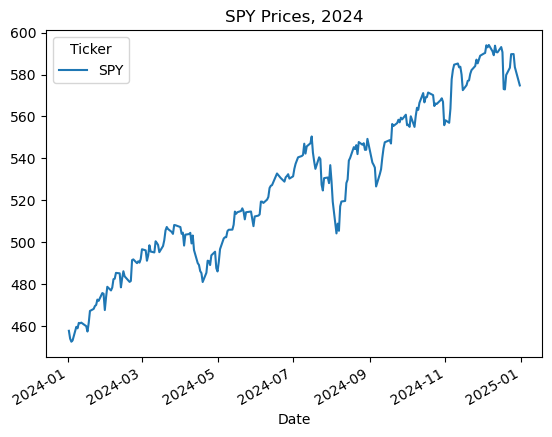

In [9]:
prices.plot(title="SPY Prices, 2024")

In [11]:
pit.show()


In [12]:
returns=prices.pct_change().dropna()


In [14]:
print(returns.head(15))


Ticker           SPY
Date                
2024-01-03 -0.008167
2024-01-04 -0.003221
2024-01-05  0.001370
2024-01-08  0.014276
2024-01-09 -0.001517
2024-01-10  0.005655
2024-01-11 -0.000441
2024-01-12  0.000693
2024-01-16 -0.003671
2024-01-17 -0.005559
2024-01-18  0.008893
2024-01-19  0.012466
2024-01-22  0.002114
2024-01-23  0.002916
2024-01-24  0.001093


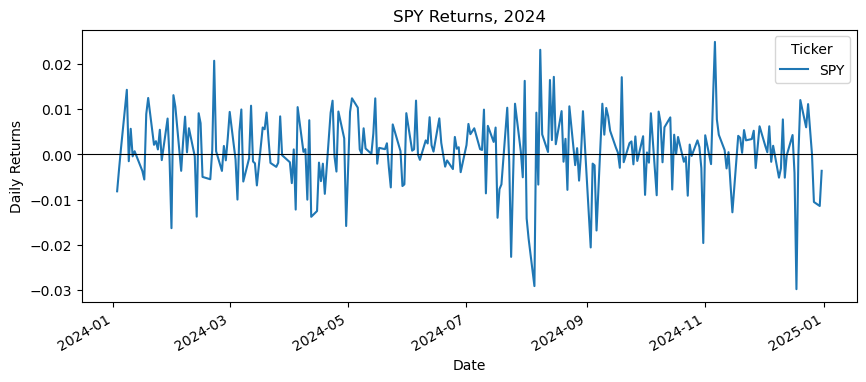

In [15]:
returns.plot(title="SPY Returns, 2024", figsize=(10,4))
pit.axhline(0,color='black', lw=0.8) # the zero line
pit.ylabel("Daily Returns")
pit.show()

In [ ]:
growth=100*(1+returns).cumprod()

In [19]:
growth

Ticker,SPY
Date,
2024-01-03,99.183318
2024-01-04,98.863854
2024-01-05,98.999268
2024-01-08,100.412589
2024-01-09,100.260238
...,...
2024-12-24,128.850754
2024-12-26,128.859329
2024-12-27,127.502886


In [17]:
print("$100 grew to", round(growth.iloc[-1],2))

$100 grew to Ticker
SPY    125.59
Name: 2024-12-31 00:00:00, dtype: float64


In [20]:
daily_volatility=returns.std()
yearly_volatility=daily_volatility*np.sqrt(252)

In [29]:
print(f"Daily volatility: {daily_volatility.iloc[0]:.2%}")

Daily volatility: 0.79%


In [31]:
daily_volatility

Ticker
SPY    0.007923
dtype: float64

In [32]:
rolling_volatility=returns.rolling(21).std()*np.sqrt(252)

AttributeError: module 'matplotlib.pyplot' has no attribute 'ylable'

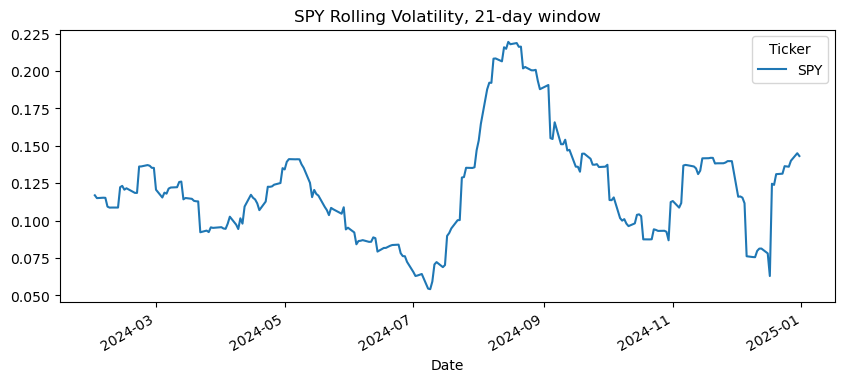

In [33]:
rolling_volatility.plot(title="SPY Rolling Volatility, 21-day window", figsize=(10,4))
pit.ylable("Yearly Volatility")
pit.show()
